#Terms of Use
By using this colab to download the brain dataset (i.e., data including fMRI, images, labels), you agree to the following terms:

1. You will use the Datasets only for non-commercial research and educational purposes.
2. You will NOT distribute the Datasets or any parts thereof.
3. Massachusetts Institute of Technology make no representations or warranties regarding the datasets, including but not limited to warranties of non-infringement or fitness for a particular purpose.
4. You accept full responsibility for your use of the datasets and shall defend and indemnify Massachusetts Institute of Technology and International Business Machines Corporation, including its employees, officers and agents, against any and all claims arising from your use of the datasets, including but not limited to your use of any copyrighted images that you may create from the datasets.
5. You will treat people appearing in this data with respect and dignity.
6. This data comes with no warranty or guarantee of any kind, and you accept full liability.

# Predicting fMRI responses from Algonauts2021 dataset

**Goal:** Here we show how to prepare submission for Algonauts 2021 challenge using AlexNet as an example.

This notebook is organized as follows:

1. Loading fMRI responses to videos and visualizing in glass brain using nilearn.
2. Feedforward the videos from stimulus set to the AlexNet model pretrained on Imagenet dataset to extract AlexNet activations from different layers and apply PCA for dimensionality reduction.
3.   Train a linear regression to predict fMRI responses from AlexNet activations.
4.   Evaluate the model by comparing the correlation between predicted and recorded fMRI responses on validation set.
5. Generate predicted fMRI responses to test videos for all subjects all ROIs
6. Preparing submission files for codalab



In [ ]:
#@title Installations
%%capture

!pip install nilearn
!pip install decord

In [ ]:
#@title Imports
import glob
import numpy as np
import urllib
import torch
import cv2
import argparse
import time
import random
import matplotlib.pyplot as plt
import nibabel as nib
import pickle
from nilearn import plotting
from tqdm import tqdm
from torchvision import transforms as trn
import os
from PIL import Image
from sklearn.preprocessing import StandardScaler
from torch.autograd import Variable as V
from sklearn.decomposition import PCA, IncrementalPCA
import torch.nn as nn
import torch.utils.model_zoo as model_zoo
import torch.nn.functional as F
from nilearn import datasets
from nilearn import surface
from decord import VideoReader
from decord import cpu

Get the dropbox link to download dataset by filling this [google form](https://forms.gle/qq9uqqu6SwN8ytxQ9).

In [ ]:
#@title Enter the download link and run the cell
download_link = "'https://www.dropbox.com/s/agxyxntrbwko7t1/participants_data.zip?dl=1'" #@param {type:"string"}
os.environ["download_link"] = download_link
!echo $download_link
!wget -O participants_data.zip -c $download_link
!unzip participants_data.zip
!wget -O example.nii -c https://github.com/Neural-Dynamics-of-Visual-Cognition-FUB/Algonauts2021_devkit/raw/main/example.nii
!wget -c https://raw.githubusercontent.com/Neural-Dynamics-of-Visual-Cognition-FUB/Algonauts2021_devkit/main/class_names_ImageNet.txt

In [ ]:
#@title Utility functions for data loading
def save_dict(di_, filename_):
    with open(filename_, 'wb') as f:
        pickle.dump(di_, f)

def load_dict(filename_):
    with open(filename_, 'rb') as f:
        u = pickle._Unpickler(f)
        u.encoding = 'latin1'
        ret_di = u.load()
    return ret_di

def visualize_activity(vid_id,sub):
  fmri_dir = './participants_data_v2021'
  track = "full_track"
  results_dir = '/content/'
  track_dir = os.path.join(fmri_dir, track)
  sub_fmri_dir = os.path.join(track_dir, sub)
  fmri_train_all,voxel_mask = get_fmri(sub_fmri_dir,"WB")
  visual_mask_3D = np.zeros((78,93,71))
  visual_mask_3D[voxel_mask==1]= fmri_train_all[vid_id,:]
  brain_mask = '/content/example.nii'
  nii_save_path =  os.path.join(results_dir, 'vid_activity.nii')
  saveasnii(brain_mask,nii_save_path,visual_mask_3D)
  plotting.plot_glass_brain(nii_save_path,
                          title='fMRI response',plot_abs=False,
                          display_mode='lyr',colorbar=True)

def get_activations(activations_dir, layer_name):
    """This function loads neural network features/activations (preprocessed using PCA) into a
    numpy array according to a given layer.
    Parameters
    ----------
    activations_dir : str
        Path to PCA processed Neural Network features
    layer_name : str
        which layer of the neural network to load,
    Returns
    -------
    train_activations : np.array
        matrix of dimensions #train_vids x #pca_components
        containing activations of train videos
    test_activations : np.array
        matrix of dimensions #test_vids x #pca_components
        containing activations of test videos
    """

    train_file = os.path.join(activations_dir,"train_" + layer_name + ".npy")
    test_file = os.path.join(activations_dir,"test_" + layer_name + ".npy")
    train_activations = np.load(train_file)
    test_activations = np.load(test_file)
    scaler = StandardScaler()
    train_activations = scaler.fit_transform(train_activations)
    test_activations = scaler.fit_transform(test_activations)

    return train_activations, test_activations

def get_fmri(fmri_dir, ROI):
    """This function loads fMRI data into a numpy array for to a given ROI.
    Parameters
    ----------
    fmri_dir : str
        path to fMRI data.
    ROI : str
        name of ROI.
    Returns
    -------
    np.array
        matrix of dimensions #train_vids x #repetitions x #voxels
        containing fMRI responses to train videos of a given ROI
    """


    # Loading ROI data
    ROI_file = os.path.join(fmri_dir, ROI + ".pkl")
    ROI_data = load_dict(ROI_file)

    # averaging ROI data across repetitions
    ROI_data_train = np.mean(ROI_data["train"], axis = 1)
    if ROI == "WB":
        voxel_mask = ROI_data['voxel_mask']
        return ROI_data_train, voxel_mask

    return ROI_data_train

def saveasnii(brain_mask,nii_save_path,nii_data):
    img = nib.load(brain_mask)
    nii_img = nib.Nifti1Image(nii_data, img.affine, img.header)
    nib.save(nii_img, nii_save_path)

The above matrix shows each individual voxel's (columns) response to 1000 videos (rows). To find out more details about how the fMRI data were preprocessed please click [here](http://algonauts.csail.mit.edu/brainmappingandanalysis.html).

Visualize a given video (with id from 0-999) and its corresponding brain activity

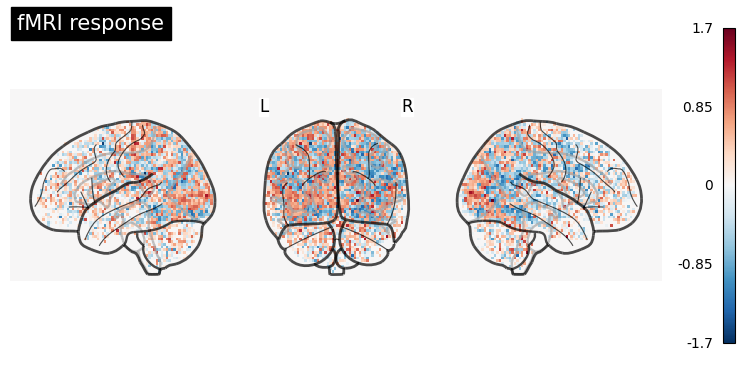

In [ ]:
#@title Visualize corresponding brain response
vid_id=0
sub="sub01"
visualize_activity(vid_id,sub)

# Vision Model definition (AlexNet)

Run the next cell to define the architecture of the model using pytorch.

In [ ]:
#@title AlexNet
__all__ = ['AlexNet', 'alexnet']


model_urls = {
    'alexnet': 'https://download.pytorch.org/models/alexnet-owt-4df8aa71.pth',
}


class AlexNet(nn.Module):

    def __init__(self, num_classes=1000):
        super(AlexNet, self).__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=11, stride=4, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            )
        self.conv2 = nn.Sequential(
            nn.Conv2d(64, 192, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            )
        self.conv3 = nn.Sequential(
            nn.Conv2d(192, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            )
        self.conv4 = nn.Sequential(
            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            )
        self.conv5 = nn.Sequential(
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            )
        self.fc6 = nn.Sequential(
            nn.Dropout(),
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            )
        self.fc7 =nn.Sequential(
            nn.Dropout(),
            nn.Linear(4096, 4096),
            )
        self.fc8 = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.Linear(4096, num_classes),
            )

    def forward(self, x):
        out1 = self.conv1(x)
        out2 = self.conv2(out1)
        out3 = self.conv3(out2)
        out4 = self.conv4(out3)
        out5 = self.conv5(out4)

        out5_reshaped = out5.view(out5.size(0), 256 * 6 * 6)
        out6= self.fc6(out5_reshaped)
        out7= self.fc7(out6)
        out8 = self.fc8(out7)
        return out1, out2, out3,out4, out5, out6,out7,out8


def alexnet(pretrained=False, **kwargs):
    r"""AlexNet model architecture from the
    `"One weird trick..." <https://arxiv.org/abs/1404.5997>`_ paper.
    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
    """
    model = AlexNet(**kwargs)
    if pretrained:
        model.load_state_dict(model_zoo.load_url(model_urls['alexnet']))
    return model

#Feature Extraction
Run the next cell to extract Alexnet activations on the videos from the stimulus set. We will use these later to train a regression for predicting fMRI responses.

In [ ]:
#@title Functions for loading videos and extracting features
seed = 42
# Torch RNG
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
# Python RNG
np.random.seed(seed)
random.seed(seed)

def load_alexnet(model_checkpoints):
    """This function initializes an Alexnet and load
    its weights from a pretrained model
    ----------
    model_checkpoints : str
        model checkpoints location.
    Returns
    -------
    model
        pytorch model of alexnet
    """


    model = alexnet()
    model_file = model_checkpoints
    checkpoint = torch.load(model_file, map_location=lambda storage, loc: storage, weights_only=False)
    model_dict =["conv1.0.weight", "conv1.0.bias", "conv2.0.weight", "conv2.0.bias", "conv3.0.weight", "conv3.0.bias", "conv4.0.weight", "conv4.0.bias", "conv5.0.weight", "conv5.0.bias", "fc6.1.weight", "fc6.1.bias", "fc7.1.weight", "fc7.1.bias", "fc8.1.weight", "fc8.1.bias"]
    state_dict={}
    i=0
    for k,v in checkpoint.items():
        state_dict[model_dict[i]] =  v
        i+=1

    model.load_state_dict(state_dict)
    if torch.cuda.is_available():
        model.cuda()
    model.eval()
    return model

def print_alexnet_predictions(output):
    with open('class_names_ImageNet.txt') as labels:
        classes = [i.strip() for i in labels.readlines()]

    # sort the probability vector in descending order
    sorted, indices = torch.sort(output, descending=True)
    percentage = F.softmax(output, dim=1)[0] * 100.0
    # obtain the first 5 classes (with the highest probability) the input belongs to
    results = [(classes[i], percentage[i].item()) for i in indices[0][:5]]
    for i in range(5):
        print('{}: {:.4f}%'.format(results[i][0], results[i][1]))


def sample_video_from_mp4(file, num_frames=16):
    """This function takes a mp4 video file as input and returns
    a list of uniformly sampled frames (PIL Image).
    Parameters
    ----------
    file : str
        path to mp4 video file
    num_frames : int
        how many frames to select using uniform frame sampling.
    Returns
    -------
    images: list of PIL Images
    num_frames: int
        number of frames extracted
    """
    images = list()
    vr = VideoReader(file, ctx=cpu(0))
    total_frames = len(vr)
    indices = np.linspace(0,total_frames-1,num_frames,dtype=int)
    for seg_ind in indices:
        images.append(Image.fromarray(vr[seg_ind].asnumpy()))

    return images,num_frames

def get_activations_and_save(model, video_list, activations_dir):
    """This function generates Alexnet features and save them in a specified directory.
    Parameters
    ----------
    model :
        pytorch model : alexnet.
    video_list : list
        the list contains path to all videos.
    activations_dir : str
        save path for extracted features.
    """

    resize_normalize = trn.Compose([
            trn.Resize((224,224)),
            trn.ToTensor(),
            trn.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

    for video_file in tqdm(video_list):
        vid,num_frames = sample_video_from_mp4(video_file)
        video_file_name = os.path.split(video_file)[-1].split(".")[0]
        activations = []
        for frame,img in enumerate(vid):
            input_img = V(resize_normalize(img).unsqueeze(0))
            if torch.cuda.is_available():
                input_img=input_img.cuda()
            x = model.forward(input_img)
            for i,feat in enumerate(x):
                if frame==0:
                    if i==7:
                        print("\nTop-5 Predictions for the video id: ", video_file_name)
                        print_alexnet_predictions(feat)
                    activations.append(feat.data.cpu().numpy().ravel())
                else:
                    activations[i] =  activations[i] + feat.data.cpu().numpy().ravel()
        for layer in range(len(activations)):
            save_path = os.path.join(activations_dir, video_file_name+"_"+"layer" + "_" + str(layer+1) + ".npy")
            avg_layer_activation = activations[layer]/float(num_frames)
            np.save(save_path,avg_layer_activation)

def do_PCA_and_save(activations_dir, save_dir):
    """This function preprocesses Neural Network features using PCA and save the results
    in  a specified directory
.
    Parameters
    ----------
    activations_dir : str
        save path for extracted features.
    save_dir : str
        save path for extracted PCA features.
    """

    layers = ['layer_1','layer_2','layer_3','layer_4','layer_5','layer_6','layer_7','layer_8']
    n_components = 100
    if not os.path.exists(save_dir):
        os.makedirs(save_dir)
    for layer in tqdm(layers):
        activations_file_list = glob.glob(activations_dir +'/*'+layer+'.npy')
        activations_file_list.sort()
        feature_dim = np.load(activations_file_list[0])
        x = np.zeros((len(activations_file_list),feature_dim.shape[0]))
        for i,activation_file in enumerate(activations_file_list):
            temp = np.load(activation_file)
            x[i,:] = temp
        x_train = x[:1000,:]
        x_test = x[1000:,:]
        print(x_train.shape,layer)
        start_time = time.time()
        x_test = StandardScaler().fit_transform(x_test)
        x_train = StandardScaler().fit_transform(x_train)
        ipca = PCA(n_components=n_components,random_state=seed)
        ipca.fit(x_train)

        x_train = ipca.transform(x_train)
        x_test = ipca.transform(x_test)
        train_save_path = os.path.join(save_dir,"train_"+layer)
        test_save_path = os.path.join(save_dir,"test_"+layer)
        np.save(train_save_path,x_train)
        np.save(test_save_path,x_test)

In [ ]:
video_dir = '/content/AlgonautsVideos268_All_30fpsmax'
video_list = glob.glob(video_dir + '/*.mp4')
video_list.sort()
print('Total Number of Videos: ', len(video_list))

Total Number of Videos:  1102


In [ ]:


video_dir = '/content/AlgonautsVideos268_All_30fpsmax'
video_list = glob.glob(video_dir + '/*.mp4')
video_list.sort()
print('Total Number of Videos: ', len(video_list))
save_dir = "/content/activations_alexnet"
# load Alexnet
# Download pretrained Alexnet from:
# https://download.pytorch.org/models/alexnet-owt-4df8aa71.pth
# and save in the current directory
checkpoint_path = "/content/alexnet.pth"
if not os.path.exists(checkpoint_path):
    url = "https://download.pytorch.org/models/alexnet-owt-4df8aa71.pth"
    urllib.request.urlretrieve(url, "/content/alexnet.pth")
model = load_alexnet(checkpoint_path)

# get and save activations

activations_dir = os.path.join(save_dir)
if not os.path.exists(activations_dir):
    os.makedirs(activations_dir)
print("-------------Saving activations ----------------------------")
get_activations_and_save(model, video_list, activations_dir)

Total Number of Videos:  1102
-------------Saving activations ----------------------------


  0%|          | 0/1102 [00:00<?, ?it/s]


Top-5 Predictions for the video id:  0001_0-0-1-6-7-2-8-0-17500167280
red-breasted merganser, Mergus serrator: 47.7814%
American coot, marsh hen, mud hen, water hen, Fulica americana: 31.1670%
oystercatcher, oyster catcher: 4.4099%
drake: 3.4130%
dowitcher: 1.9694%


  0%|          | 1/1102 [00:01<28:11,  1.54s/it]


Top-5 Predictions for the video id:  0002_0-0-4-3146384004
Bouvier des Flandres, Bouviers des Flandres: 28.6873%
Scottish deerhound, deerhound: 9.3555%
standard schnauzer: 6.3326%
bulletproof vest: 5.2905%
Irish wolfhound: 3.4212%


  0%|          | 2/1102 [00:02<22:15,  1.21s/it]

... (2,196 outputs left out)


Top-5 Predictions for the video id:  1101_flickr-scrambldmeggs-3606262338_21
dam, dike, dyke: 53.6947%
ice bear, polar bear, Ursus Maritimus, Thalarctos maritimus: 4.3666%
sandbar, sand bar: 3.4464%
fountain: 2.6984%
breakwater, groin, groyne, mole, bulwark, seawall, jetty: 2.6769%


100%|█████████▉| 1101/1102 [19:13<00:01,  1.11s/it]


Top-5 Predictions for the video id:  1102_meta_R-5602303_250
disk brake, disc brake: 25.8049%
moped: 21.3319%
motor scooter, scooter: 8.4989%
horse cart, horse-cart: 7.1065%
crash helmet: 5.6486%


100%|██████████| 1102/1102 [19:14<00:00,  1.05s/it]


In [ ]:
#activations_dir
save_dir

'/content/activations_alexnet'

In [ ]:
# preprocessing using PCA and save
pca_dir = os.path.join(save_dir, 'pca_100')
print("-------------performing  PCA----------------------------")
do_PCA_and_save(activations_dir, pca_dir)

-------------performing  PCA----------------------------


  0%|          | 0/8 [00:00<?, ?it/s]

(1000, 46656) layer_1


 12%|█▎        | 1/8 [00:09<01:09,  9.93s/it]

(1000, 32448) layer_2


 25%|██▌       | 2/8 [00:18<00:54,  9.09s/it]

... (8 outputs left out)

(1000, 4096) layer_7


 88%|████████▊ | 7/8 [00:50<00:04,  4.62s/it]

(1000, 1000) layer_8


100%|██████████| 8/8 [00:50<00:00,  6.37s/it]


In [ ]:
# MLP Approach
class FancyStuff(nn.Module):


  def __init__(self,input_layer_size,output_layer_size):
    """
    Initialize parameters of FancyStuff

    Args:
      None

    Returns:
      Nothing
    """
    super(FancyStuff, self).__init__()
    #self.fc1 = nn.Linear(input_layer_size, 500) #slightly smaller and multiples of 2 265
    #self.fc2 = nn.Linear(500,200) #128
    #self.fc3 = nn.Linear(200,200) #64
    #self.fc4 = nn.Linear(200, output_layer_size)
    self.fc1 = nn.Linear(input_layer_size, 256) #slightly smaller and multiples of 2 265
    self.fc2 = nn.Linear(256,128) #128
    self.fc3 = nn.Linear(128,64) #64
    self.fc4 = nn.Linear(64, output_layer_size)

  def forward(self, x):
    """
    Forward Pass of FancyStuff

    Args:
      x: torch.tensor
        Input features

    Returns:
      output: torch.tensor
        Outputs/Predictions
    """
    x = x.view(x.shape[0],-1)
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    x = F.relu(self.fc3(x))
    x = self.fc4(x)
    output = x
    return output

In [ ]:
# Set random seed

# @markdown Executing `set_seed(seed=seed)` you are setting the seed

# For DL its critical to set the random seed so that students can have a
# baseline to compare their results to expected results.
# Read more here: https://pytorch.org/docs/stable/notes/randomness.html

# Call `set_seed` function in the exercises to ensure reproducibility.
import random
import torch

def set_seed(seed=None, seed_torch=True):
  """
  Function that controls randomness. NumPy and random modules must be imported.

  Args:
    seed : Integer
      A non-negative integer that defines the random state. Default is `None`.
    seed_torch : Boolean
      If `True` sets the random seed for pytorch tensors, so pytorch module
      must be imported. Default is `True`.

  Returns:
    Nothing.
  """
  if seed is None:
    seed = np.random.choice(2 ** 32)
  random.seed(seed)
  np.random.seed(seed)
  if seed_torch:
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

  print(f'Random seed {seed} has been set.')


# In case that `DataLoader` is used
def seed_worker(worker_id):
  """
  DataLoader will reseed workers following randomness in
  multi-process data loading algorithm.

  Args:
    worker_id: integer
      ID of subprocess to seed. 0 means that
      the data will be loaded in the main process
      Refer: https://pytorch.org/docs/stable/data.html#data-loading-randomness for more details

  Returns:
    Nothing
  """
  worker_seed = torch.initial_seed() % 2**32
  np.random.seed(worker_seed)
  random.seed(worker_seed)
  # Set device (GPU or CPU). Execute `set_device()`
# especially if torch modules used.
# Inform the user if the notebook uses GPU or CPU.
def set_device():
  """
  Set the device. CUDA if available, CPU otherwise
  Args:
    None
  Returns:
    Nothing
  """
  device = "cuda" if torch.cuda.is_available() else "cpu"
  if device != "cuda":
    print("WARNING: For this notebook to perform best, "
        "if possible, in the menu under `Runtime` -> "
        "`Change runtime type.`  select `GPU` ")
  else:
    print("GPU is enabled in this notebook.")
  return device
SEED = 2025
set_seed(seed=SEED)
DEVICE = set_device()

Random seed 2025 has been set.


In [ ]:
##All MLP functions
def calculate_frobenius_norm(model):
  """
  Function to calculate frobenius norm
  Args:
    model: nn.module
      Neural network instance
  Returns:
    norm: float
      Frobenius norm
  """
  ####################################################################
  # Fill in all missing code below (...),
  # then remove or comment the line below to test your function
  #raise NotImplementedError("Define `calculate_frobenius_norm` function")
  ####################################################################
  norm = 0.0
  # Sum the square of all parameters
  for param in model.parameters():
    norm += torch.sum(param**2)
  # Take a square root of the sum of squares of all the parameters
  norm = torch.sqrt(norm)
  return norm


# Seed added for reproducibility
set_seed(seed=SEED)
## uncomment below to test your code
net = nn.Linear(10, 1)
print(f'Frobenius norm of Single Linear Layer: {calculate_frobenius_norm(net)}')

def r2_score(y_pred, y_true):
    """
    Compute the R^2 (coefficient of determination)

    Args:
      y_pred: torch.Tensor (predicted values)
      y_true: torch.Tensor (ground truth)

    Returns:
      r2: float
    """
    y_true_mean = torch.mean(y_true)
    ss_tot = torch.sum((y_true - y_true_mean) ** 2)
    ss_res = torch.sum((y_true - y_pred) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    return r2.item()

# MLP Approach
class FancyStuff(nn.Module):


  def __init__(self,input_layer_size,output_layer_size):
    """
    Initialize parameters of FancyStuff

    Args:
      None

    Returns:
      Nothing
    """
    super(FancyStuff, self).__init__()
    #self.fc1 = nn.Linear(input_layer_size, 500) #slightly smaller and multiples of 2 265
    #self.fc2 = nn.Linear(500,200) #128
    #self.fc3 = nn.Linear(200,200) #64
    #self.fc4 = nn.Linear(200, output_layer_size)
    self.fc1 = nn.Linear(input_layer_size, 256) #slightly smaller and multiples of 2 265
    self.fc2 = nn.Linear(256,128) #128
    self.fc3 = nn.Linear(128,64) #64
    self.fc4 = nn.Linear(64, output_layer_size)

  def forward(self, x):
    """
    Forward Pass of FancyStuff

    Args:
      x: torch.tensor
        Input features

    Returns:
      output: torch.tensor
        Outputs/Predictions
    """
    x = x.view(x.shape[0],-1)
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    x = F.relu(self.fc3(x))
    x = self.fc4(x)
    output = x
    return output

import torch.optim as optim
def train(args, model, train_loader, optimizer,
          reg_function1=None, reg_function2=None, criterion=F.mse_loss):
  """
  Trains the current input model using the data
  from Train_loader and Updates parameters for a single pass

  Args:
    args: dictionary
      Dictionary with epochs: 200, lr: 5e-3, momentum: 0.9, device: DEVICE
    model: nn.module
      Neural network instance
    train_loader: torch.loader
      Input dataset
    optimizer: function
      Optimizer
    reg_function1: function
      Regularisation function [default: None]
    reg_function2: function
      Regularisation function [default: None]
    criterion: function
      Specifies loss function [default: nll_loss]

  Returns:
    model: nn.module
      Neural network instance post training
  """
  device = args['device']
  model.train()
  for batch_idx, (data, target) in enumerate(train_loader):
    data, target = data.to(device), target.to(device)
    optimizer.zero_grad()
    output = model(data)
    #print(output.shape,target.shape)
    if reg_function1 is None:
      loss = criterion(output, target)
    elif reg_function2 is None:
      loss = criterion(output, target)+args['lambda']*reg_function1(model)
    else:
      loss = criterion(output, target) + args['lambda1']*reg_function1(model) + args['lambda2']*reg_function2(model)
    loss.backward()
    optimizer.step()

  return model


def test(model, test_loader, criterion=F.mse_loss, device='cpu', return_r2=True):
  """
  Tests the current model

  Returns:
    test_loss: float
      Test loss
    r2: float (optional)
      R^2 score
  """
  model.eval()
  test_loss = 0
  all_preds = []
  all_targets = []

  with torch.no_grad():
    for data, target in test_loader:
      data, target = data.to(device), target.to(device)
      output = model(data)
      test_loss += criterion(output, target, reduction='sum')
      if return_r2:
        all_preds.append(output)
        all_targets.append(target)

  test_loss /= len(test_loader.dataset)

  if return_r2:
    y_pred = torch.cat(all_preds, dim=0)
    y_true = torch.cat(all_targets, dim=0)
    r2 = r2_score(y_pred, y_true)
    return test_loss.item(), r2
  else:
    return test_loss.item()



def main(args, model, train_loader, test_loader, reg_function1=None, reg_function2=None):
  """
  Trains the model with train_loader and
  tests the learned model using val_loader

  Args:
    args: dictionary
      Dictionary with epochs: 200, lr: 5e-3, momentum: 0.9, device: DEVICE
    model: nn.module
      Neural network instance
    train_loader: torch.loader
      Train dataset
    val_loader: torch.loader
      Validation set
    reg_function1: function
      Regularisation function [default: None]
    reg_function2: function
      Regularisation function [default: None]

  Returns:
    val_acc_list: list
      Log of validation accuracy
    train_acc_list: list
      Log of training accuracy
    param_norm_list: list
      Log of frobenius norm
    trained_model: nn.module
      Trained model/model post training
  """
  #os.path.join(activations_dir,'pca_100')
  #train_activations,test_activations = get_activations(pca_dir, layer)
  #track = "mini_track"
  #fmri_dir = os.path.join(fmri_dir, track)
  #sub_fmri_dir = os.path.join(fmri_dir, sub)
  #fmri_train_all = get_fmri(sub_fmri_dir,ROI)
  #num_voxels = fmri_train_all.shape[1]
  #fmri_train = fmri_train_all[:900,:]
  #fmri_test = fmri_train_all[900:,:]


  device = args['device']

  model = model.to(device)
  optimizer = optim.SGD(model.parameters(), lr=args['lr'],
                        momentum=args['momentum'])

  val_mse_list, train_mse_list, param_norm_list = [], [], []
  val_r2_list, train_r2_list = [], []

  for epoch in tqdm(range(args['epochs'])):
    trained_model = train(args, model, train_loader, optimizer,
                              reg_function1=reg_function1,
                              reg_function2=reg_function2)

    train_mse, train_r2 = test(trained_model, train_loader, device=device, return_r2=True)
    val_mse, val_r2 = test(trained_model, test_loader, device=device, return_r2=True)

    param_norm = calculate_frobenius_norm(trained_model)

    train_mse_list.append(train_mse)
    val_mse_list.append(val_mse)
    train_r2_list.append(train_r2)
    val_r2_list.append(val_r2)
    param_norm_list.append(param_norm)


  return val_mse_list, train_mse_list, param_norm_list, trained_model, val_r2_list, train_r2_list

# Set the arguments
args = {
    'epochs': 100,
    'lr': 5e-3,
    'momentum': 0.9,
    'device': DEVICE
}

def evaluate_mlp(train_loader,test_loader):
  # Initialize the network
  set_seed(seed=SEED)
  model = FancyStuff(input_layer_size=100, output_layer_size=1) #change to 9 for all regions

  start_time = time.time()

  # Train the network
  val_mse_list, train_mse_list, param_norm_list, trained_model, val_r2_list, train_r2_list= main(args=args,
                                                model=model,
                                                train_loader=train_loader,
                                                test_loader=test_loader)


  import numpy as np

  train_rmse_pure = [np.sqrt(mse) for mse in train_mse_list]
  val_rmse_pure = [np.sqrt(mse) for mse in val_mse_list]

  #plt.figure(figsize=(8, 6))
  #plt.plot(val_rmse_pure, label='Val RMSE', c='blue', ls='dashed')
  #plt.plot(train_rmse_pure, label='Train RMSE', c='blue', ls='solid')
  #plt.axhline(y=min(val_rmse_pure), c='green', ls='dashed', label='Min Val RMSE')
  #plt.title('Memorization Curve (RMSE)')
  #plt.ylabel('RMSE')
  #plt.xlabel('Epoch')
  #plt.legend()
  #plt.show()

  #plt.figure(figsize=(8, 6))
  #plt.plot(val_r2_list, label='Val R²', c='red', ls='dashed')
  #plt.plot(train_r2_list, label='Train R²', c='red', ls='solid')
  #plt.title('R² Score Over Epochs')
  #plt.ylabel('R²')
  #plt.xlabel('Epoch')
  #plt.legend()
  #plt.show()
  return(train_r2_list,val_r2_list,train_rmse_pure,val_rmse_pure)
#print(correlation(train_rmse_pure, val_rmse_pure))
import torch
from torch.utils.data import Dataset, DataLoader
class BrainDataset(Dataset):
    def __init__(self, activations, fmri):
        self.activations = torch.tensor(activations, dtype=torch.float32)
        self.fmri = torch.tensor(fmri, dtype=torch.float32)
        assert len(self.activations) == len(self.fmri), "Mismatch in sample size"
    def __len__(self):
        return len(self.activations)
    def __getitem__(self, idx):
        return self.activations[idx], self.fmri[idx]


Random seed 2025 has been set.
Frobenius norm of Single Linear Layer: 0.6532154083251953


In [ ]:
ROI="V1"
os.path.join(activations_dir,'pca_100')
train_activations,test_activations = get_activations(pca_dir, 'layer_1')
track = "mini_track"
fmri_dir='/content/participants_data_v2021'
fmri_dir = os.path.join(fmri_dir, track)
sub_fmri_dir = os.path.join(fmri_dir, sub)
fmri_train_all = get_fmri(sub_fmri_dir,ROI)
num_voxels = fmri_train_all.shape[1]

activations_train = train_activations[:900,:]
activations_test = train_activations[900:,:]
num_features = activations_train.shape[1]

In [ ]:
#roi_list=["V1","V2","V3","V4","LOC","EBA","FFA","STS","PPA"]
roi_list=["V1"]
sub_list_train=["sub01","sub02","sub03","sub04","sub05","sub06","sub07","sub08"]
sub_list_test=["sub09","sub10"]
sub_list_all=["sub01","sub02","sub03","sub04","sub05","sub06","sub07","sub08","sub09","sub10"]
fmri_mean_all=[]
fmri_train=[]
activations_train=[]
fmri_mean_all_test=[]
fmri_test=[]
activations_test=[]
track="mini_track"
fmri_dir='/content/participants_data_v2021'
fmri_dir = os.path.join(fmri_dir, track)
r2_score_list_train=[]
r2_score_list_test=[]
rmse_list_train=[]
rmse_list_test=[]
it=[]
roi_list_list=[]
#roi_list=[]
for i_test_s,testsub in enumerate(sub_list_all):
  print(i_test_s,testsub)
  for i_s, sub in enumerate(sub_list_all):
    print(i_s)
    sub_fmri_dir = os.path.join(fmri_dir, sub)
    if i_s != i_test_s:
      #sub_fmri_dir = os.path.join(fmri_dir, sub)
      for i_r,ROI in enumerate(roi_list):
        fmri_train_all_temp = get_fmri(sub_fmri_dir,ROI)
        #print(fmri_train_all_temp.shape)
        fmri_train_all_temp_new=torch.mean(torch.tensor(fmri_train_all_temp),dim=1,keepdim=True)
        #print(fmri_train_all_temp_new.shape)
        if i_r==0:
          fmri_mean_all=fmri_train_all_temp_new
        else:
          fmri_mean_all=torch.cat((fmri_mean_all, fmri_train_all_temp_new), 1)
      if i_s==0 or (i_test_s==0 and i_s==1):
        fmri_train=fmri_mean_all
        activations_train=torch.tensor(train_activations[0:1000,:])
      else:
        #print(i_s,fmri_train,fmri_mean_all)
        fmri_train=torch.cat((fmri_train,fmri_mean_all), 0)
        activations_train=torch.cat((activations_train,torch.tensor(train_activations[0:1000,:])), 0)
      #print(fmri_train.shape)
    else:

      for i_r,ROI in enumerate(roi_list):
        fmri_test_all_temp = get_fmri(sub_fmri_dir,ROI)
        #print(fmri_test_all_temp.shape)
        fmri_test_all_temp_new=torch.mean(torch.tensor(fmri_test_all_temp),dim=1,keepdim=True)
        #print(fmri_test_all_temp_new.shape)
        if i_r==0:
          fmri_mean_all_test=fmri_test_all_temp_new
        else:
          fmri_mean_all_test=torch.cat((fmri_mean_all_test, fmri_test_all_temp_new), 1)
      #if i_s==0:
        fmri_test=fmri_mean_all_test
        activations_test=torch.tensor(train_activations[0:1000,:])
      #else:
        #fmri_test=torch.cat((fmri_test,fmri_mean_all), 0)
        #activations_test=torch.cat((activations_test,torch.tensor(train_activations[0:1000,:])), 0)
  print(fmri_test.shape,fmri_train.shape,activations_train.shape,activations_test.shape)
  train_dataset = BrainDataset(activations_train, fmri_train)
  test_dataset = BrainDataset(activations_test, fmri_test)
  train_loader = DataLoader(train_dataset, batch_size=100, shuffle=True)
  test_loader = DataLoader(test_dataset, batch_size=100, shuffle=False)
  train_r2_list,val_r2_list,train_rmse_pure,val_rmse_pure=evaluate_mlp(train_loader,test_loader)
  r2_score_list_train.append(train_r2_list)
  r2_score_list_test.append(val_r2_list)
  rmse_list_train.append(train_rmse_pure)
  rmse_list_test.append(val_rmse_pure)
  it.append(i_s)
  roi_list_list.append(ROI)
  #fmri_train = fmri_mean_all[:900,:]
  #fmri_test = fmri_mean_all[900:,:]

0 sub01
0
1
2


/tmp/ipython-input-14-219288251.py:294: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.activations = torch.tensor(activations, dtype=torch.float32)
/tmp/ipython-input-14-219288251.py:295: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.fmri = torch.tensor(fmri, dtype=torch.float32)


3
4
5
6
7
8
9
torch.Size([1000, 1]) torch.Size([9000, 1]) torch.Size([9000, 100]) torch.Size([1000, 100])
Random seed 2025 has been set.


100%|██████████| 100/100 [00:44<00:00,  2.27it/s]


1 sub02
0
1
2
3
4
5
6
7
8
9
torch.Size([1000, 1]) torch.Size([9000, 1]) torch.Size([9000, 100]) torch.Size([1000, 100])
Random seed 2025 has been set.


100%|██████████| 100/100 [00:42<00:00,  2.33it/s]


... (12 outputs left out)

8 sub09
0
1
2
3
4
5
6
7
8
9
torch.Size([1000, 1]) torch.Size([9000, 1]) torch.Size([9000, 100]) torch.Size([1000, 100])
Random seed 2025 has been set.


100%|██████████| 100/100 [00:43<00:00,  2.29it/s]


9 sub10
0
1
2
3
4
5
6
7
8
9
torch.Size([1000, 1]) torch.Size([9000, 1]) torch.Size([9000, 100]) torch.Size([1000, 100])
Random seed 2025 has been set.


100%|██████████| 100/100 [00:42<00:00,  2.37it/s]


In [ ]:
roi_list=["V1","V2","V3","V4","LOC","EBA","FFA","STS","PPA"]
roi_list=["V1","V2","V3"]

layer_list=["layer_1","layer_2","layer_3","layer_4","layer_5","layer_6","layer_7","layer_8"]
layer_list=["layer_3","layer_5","layer_8"]
#roi_list=["V1"]
sub_list_train=["sub01","sub02","sub03","sub04","sub05","sub06","sub07","sub08"]
sub_list_test=["sub09","sub10"]
sub_list_all=["sub01","sub02","sub03","sub04","sub05","sub06","sub07","sub08","sub09","sub10"]
fmri_mean_all=[]
fmri_train=[]
activations_train=[]
fmri_mean_all_test=[]
fmri_test=[]
activations_test=[]
track="mini_track"
fmri_dir='/content/participants_data_v2021'
fmri_dir = os.path.join(fmri_dir, track)




def return_r2_rmse_means_cross_val(roi_list,fmri_dir,train_activations,sub_list_all):
  r2_score_list_train=[]
  r2_score_list_test=[]
  rmse_list_train=[]
  rmse_list_test=[]
  it=[]
  roi_list_list=[]
  #roi_list=[]
  for i_test_s,testsub in enumerate(sub_list_all):
    print(i_test_s,testsub)
    for i_s, sub in enumerate(sub_list_all):
      print(i_s)
      sub_fmri_dir = os.path.join(fmri_dir, sub)
      if i_s != i_test_s:
        #sub_fmri_dir = os.path.join(fmri_dir, sub)
        for i_r,ROI in enumerate(roi_list):
          fmri_train_all_temp = get_fmri(sub_fmri_dir,ROI)
          #print(fmri_train_all_temp.shape)
          fmri_train_all_temp_new=torch.mean(torch.tensor(fmri_train_all_temp),dim=1,keepdim=True)
          #print(fmri_train_all_temp_new.shape)
          if i_r==0:
            fmri_mean_all=fmri_train_all_temp_new
          else:
            fmri_mean_all=torch.cat((fmri_mean_all, fmri_train_all_temp_new), 1)
        if i_s==0 or (i_test_s==0 and i_s==1):
          fmri_train=fmri_mean_all
          activations_train=torch.tensor(train_activations[0:1000,:])
        else:
          #print(i_s,fmri_train,fmri_mean_all)
          fmri_train=torch.cat((fmri_train,fmri_mean_all), 0)
          activations_train=torch.cat((activations_train,torch.tensor(train_activations[0:1000,:])), 0)
        #print(fmri_train.shape)
      else:

        for i_r,ROI in enumerate(roi_list):
          fmri_test_all_temp = get_fmri(sub_fmri_dir,ROI)
          #print(fmri_test_all_temp.shape)
          fmri_test_all_temp_new=torch.mean(torch.tensor(fmri_test_all_temp),dim=1,keepdim=True)
          #print(fmri_test_all_temp_new.shape)
          if i_r==0:
            fmri_mean_all_test=fmri_test_all_temp_new
          else:
            fmri_mean_all_test=torch.cat((fmri_mean_all_test, fmri_test_all_temp_new), 1)
        #if i_s==0:
          fmri_test=fmri_mean_all_test
          activations_test=torch.tensor(train_activations[0:1000,:])
        #else:
          #fmri_test=torch.cat((fmri_test,fmri_mean_all), 0)
          #activations_test=torch.cat((activations_test,torch.tensor(train_activations[0:1000,:])), 0)
    print(fmri_test.shape,fmri_train.shape,activations_train.shape,activations_test.shape)
    train_dataset = BrainDataset(activations_train, fmri_train)
    test_dataset = BrainDataset(activations_test, fmri_test)
    train_loader = DataLoader(train_dataset, batch_size=100, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=100, shuffle=False)
    train_r2_list,val_r2_list,train_rmse_pure,val_rmse_pure=evaluate_mlp(train_loader=train_loader,test_loader=test_loader)
    r2_score_list_train.append(train_r2_list)
    r2_score_list_test.append(val_r2_list)
    rmse_list_train.append(train_rmse_pure)
    rmse_list_test.append(val_rmse_pure)
    it.append(i_s)
    roi_list_list.append(ROI)
  r2_score_test=np.array(r2_score_list_test[:][-1]).mean()
  r2_score_train=np.array(r2_score_list_train[:][-1]).mean()
  rmse_score_train=np.array(rmse_list_train[:][-1]).mean()
  rmse_score_test=np.array(rmse_list_test[:][-1]).mean()
  return r2_score_train,r2_score_test, rmse_score_train, rmse_score_test
  #fmri_train = fmri_mean_all[:900,:]
  #fmri_test = fmri_mean_all[900:,:]

arr_all=np.zeros((len(roi_list),len(layer_list)))
for i_r,roi in enumerate(roi_list):
      roi_list_here=[roi]
      for i_l,layer in enumerate(layer_list):
                train_activations,test_activations = get_activations(pca_dir, layer)
                r2_score_train,r2_score_test, rmse_score_train, rmse_score_test=return_r2_rmse_means_cross_val(roi_list_here,fmri_dir,train_activations,sub_list_all)
                arr_all[i_r,i_l]=r2_score_test
                print(r2_score_test)


/tmp/ipython-input-14-219288251.py:294: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.activations = torch.tensor(activations, dtype=torch.float32)
/tmp/ipython-input-14-219288251.py:295: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.fmri = torch.tensor(fmri, dtype=torch.float32)


0 sub01
0
1
2
3
4
5
6
7
8
9
torch.Size([1000, 1]) torch.Size([9000, 1]) torch.Size([9000, 100]) torch.Size([1000, 100])
Random seed 2025 has been set.


100%|██████████| 100/100 [00:42<00:00,  2.36it/s]


1 sub02
0
1
2
3
4
5
6
7
8
9
torch.Size([1000, 1]) torch.Size([9000, 1]) torch.Size([9000, 100]) torch.Size([1000, 100])
Random seed 2025 has been set.


100%|██████████| 100/100 [00:42<00:00,  2.36it/s]


2 sub03
0
1
2
3
4
5
6
7
8
9
torch.Size([1000, 1]) torch.Size([9000, 1]) torch.Size([9000, 100]) torch.Size([1000, 100])
Random seed 2025 has been set.


... (20 outputs left out)

100%|██████████| 100/100 [00:43<00:00,  2.32it/s]


3 sub04
0
1
2
3
4
5
6
7
8
9
torch.Size([1000, 1]) torch.Size([9000, 1]) torch.Size([9000, 100]) torch.Size([1000, 100])
Random seed 2025 has been set.


 45%|████▌     | 45/100 [00:20<00:25,  2.17it/s]


KeyboardInterrupt: 

In [ ]:
roi_list=["V1","V2","V3","V4","LOC","EBA","FFA","STS","PPA"]
#roi_list=["V1","V2","V3"]

layer_list=["layer_1","layer_2","layer_3","layer_4","layer_5","layer_6","layer_7","layer_8"]
#layer_list=["layer_3","layer_5","layer_8"]
#roi_list=["V1"]
sub_list_train=["sub01","sub02","sub03","sub04","sub05","sub06","sub07","sub08"]
sub_list_test=["sub09","sub10"]
#sub_list_all=["sub01","sub02","sub03","sub04","sub05","sub06","sub07","sub08","sub09","sub10"]
fmri_mean_all=[]
fmri_train=[]
activations_train=[]
fmri_mean_all_test=[]
fmri_test=[]
activations_test=[]
track="mini_track"
fmri_dir='/content/participants_data_v2021'
fmri_dir = os.path.join(fmri_dir, track)




def return_r2_rmse_means_train_test_split(roi_list,fmri_dir,train_activations,sub_list_train, sub_list_test):
  r2_score_list_train=[]
  r2_score_list_test=[]
  rmse_list_train=[]
  rmse_list_test=[]
  it=[]
  roi_list_list=[]
  #roi_list=[]
  #for i_test_s,testsub in enumerate(sub_list_train):
    #print(i_test_s,testsub)
  for i_s, sub in enumerate(sub_list_train):
      print(i_s)
      sub_fmri_dir = os.path.join(fmri_dir, sub)

        #sub_fmri_dir = os.path.join(fmri_dir, sub)
      for i_r,ROI in enumerate(roi_list):
          fmri_train_all_temp = get_fmri(sub_fmri_dir,ROI)
          #print(fmri_train_all_temp.shape)
          fmri_train_all_temp_new=torch.mean(torch.tensor(fmri_train_all_temp),dim=1,keepdim=True)
          #print(fmri_train_all_temp_new.shape)
          if i_r==0:
            fmri_mean_all=fmri_train_all_temp_new
          else:
            fmri_mean_all=torch.cat((fmri_mean_all, fmri_train_all_temp_new), 1)
      if i_s==0:
          print("hier")
          fmri_train=fmri_mean_all
          activations_train=torch.tensor(train_activations[0:1000,:])
      else:
          #print(i_s,fmri_train,fmri_mean_all)
          fmri_train=torch.cat((fmri_train,fmri_mean_all), 0)
          activations_train=torch.cat((activations_train,torch.tensor(train_activations[0:1000,:])), 0)
        #print(fmri_train.shape)
      #else:
  for i_s, sub in enumerate(sub_list_test):
          print(i_s)
          sub_fmri_dir = os.path.join(fmri_dir, sub)
          for i_r,ROI in enumerate(roi_list):
              fmri_test_all_temp = get_fmri(sub_fmri_dir,ROI)
              #print(fmri_test_all_temp.shape)
              fmri_test_all_temp_new=torch.mean(torch.tensor(fmri_test_all_temp),dim=1,keepdim=True)
              #print(fmri_test_all_temp_new.shape)
              if i_r==0:
                fmri_mean_all_test=fmri_test_all_temp_new
              else:
                fmri_mean_all_test=torch.cat((fmri_mean_all_test, fmri_test_all_temp_new), 1)
              if i_s==0:
                print("hier")
                fmri_test=fmri_mean_all_test
                #print(fmri_test)
                activations_test=torch.tensor(train_activations[0:1000,:])
              else:
                fmri_test=torch.cat((fmri_test,fmri_mean_all_test), 0)
                activations_test=torch.cat((activations_test,torch.tensor(train_activations[0:1000,:])), 0)
  print(fmri_test.shape,fmri_train.shape,activations_train.shape,activations_test.shape)
  train_dataset = BrainDataset(activations_train, fmri_train)
  test_dataset = BrainDataset(activations_test, fmri_test)
  train_loader = DataLoader(train_dataset, batch_size=100, shuffle=True)
  test_loader = DataLoader(test_dataset, batch_size=100, shuffle=False)
  train_r2_list,val_r2_list,train_rmse_pure,val_rmse_pure=evaluate_mlp(train_loader=train_loader,test_loader=test_loader)
  r2_score_list_train.append(train_r2_list)
  r2_score_list_test.append(val_r2_list)
  rmse_list_train.append(train_rmse_pure)
  rmse_list_test.append(val_rmse_pure)
  it.append(i_s)
  roi_list_list.append(ROI)
  print(np.array(r2_score_list_test).shape)
  r2_score_test=np.array(r2_score_list_test)
  r2_score_train=np.array(r2_score_list_train)
  rmse_score_train=np.array(rmse_list_train)
  rmse_score_test=np.array(rmse_list_test)
  #print(r2_score_test)
  return r2_score_train,r2_score_test, rmse_score_train, rmse_score_test
  #fmri_train = fmri_mean_all[:900,:]
  #fmri_test = fmri_mean_all[900:,:]

arr_all=np.zeros((len(roi_list),len(layer_list)))
for i_r,roi in enumerate(roi_list):
      roi_list_here=[roi]
      for i_l,layer in enumerate(layer_list):
                train_activations,test_activations = get_activations(pca_dir, layer)
                r2_score_train,r2_score_test, rmse_score_train, rmse_score_test=return_r2_rmse_means_train_test_split(roi_list_here,fmri_dir,train_activations,sub_list_train,sub_list_test)
                arr_all[i_r,i_l]=r2_score_test[0][-1]
                #print(r2_score_test)


/tmp/ipython-input-14-219288251.py:294: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.activations = torch.tensor(activations, dtype=torch.float32)
/tmp/ipython-input-14-219288251.py:295: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.fmri = torch.tensor(fmri, dtype=torch.float32)


0
hier
1
2
3
4
5
6
7
0
hier
1
torch.Size([2000, 1]) torch.Size([8000, 1]) torch.Size([8000, 100]) torch.Size([2000, 100])
Random seed 2025 has been set.


100%|██████████| 100/100 [00:40<00:00,  2.47it/s]
/tmp/ipython-input-14-219288251.py:294: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.activations = torch.tensor(activations, dtype=torch.float32)
/tmp/ipython-input-14-219288251.py:295: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.fmri = torch.tensor(fmri, dtype=torch.float32)


(1, 100)
0
hier
1
2
3
4
5
6
7
0
hier
1
torch.Size([2000, 1]) torch.Size([8000, 1]) torch.Size([8000, 100]) torch.Size([2000, 100])
Random seed 2025 has been set.


100%|██████████| 100/100 [00:40<00:00,  2.48it/s]
/tmp/ipython-input-14-219288251.py:294: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.activations = torch.tensor(activations, dtype=torch.float32)
/tmp/ipython-input-14-219288251.py:295: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.fmri = torch.tensor(fmri, dtype=torch.float32)


(1, 100)
0
hier
1
2
3
4
5
6
7
0
hier
1
torch.Size([2000, 1]) torch.Size([8000, 1]) torch.Size([8000, 100]) torch.Size([2000, 100])
Random seed 2025 has been set.


... (67 outputs left out)

(1, 100)
0
hier
1
2
3
4
5
6
7
0


/tmp/ipython-input-14-219288251.py:294: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.activations = torch.tensor(activations, dtype=torch.float32)
/tmp/ipython-input-14-219288251.py:295: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.fmri = torch.tensor(fmri, dtype=torch.float32)


hier
1
torch.Size([2000, 1]) torch.Size([8000, 1]) torch.Size([8000, 100]) torch.Size([2000, 100])
Random seed 2025 has been set.


 38%|███▊      | 38/100 [00:14<00:22,  2.73it/s]

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# Example data
data = arr_all # 5 ROIs, 4 layers
roi_names = roi_list
layer_names = layer_list

# Create heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(data, xticklabels=layer_names, yticklabels=roi_names, cmap='viridis', annot=True)

plt.title("Heatmap of ROIs vs Layers")
plt.xlabel("Layers")
plt.ylabel("ROIs")
plt.tight_layout()
plt.show()


In [ ]:
# Normalize per row (ROI)
row_sums = data.sum(axis=1, keepdims=True)
normalized_data = data / row_sums  # each row sums to 1

# Create heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(normalized_data, xticklabels=layer_names, yticklabels=roi_names,
            cmap='viridis', annot=True, fmt=".2f")

plt.title("Row-Normalized Heatmap (Best Prediction per ROI)")
plt.xlabel("Layers")
plt.ylabel("ROIs")
plt.tight_layout()
plt.show()

In [ ]:
import scipy.stats as stats
for i in range(0,arr_all.shape[0]):
  plt.plot(layer_list,stats.zscore(arr_all[i,:]), label=roi_list[i])
  #plt.plot(layer_list,arr_all[i,:], label=roi_list[i])

plt.xlabel("Layer Index")  # or use actual layer names if available
plt.ylabel("Z-scored Value")
plt.title("Z-scored Profiles per ROI")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Get index of max value per row
max_indices = np.argmax(data, axis=1)

# Map indices to layer names
best_layers_per_roi = [layer_names[i] for i in max_indices]

# Optionally, print results
for roi, best_layer in zip(roi_names, best_layers_per_roi):
    print(f"{roi}: Best layer = {best_layer}")


In [ ]:
np.array(r2_score_list_test[:][-1]).mean()

In [ ]:
print(fmri_train.shape)
print(fmri_test.shape)
print(train_activations.shape)
print(test_activations.shape)
print(activations_train.shape)
print(activations_test.shape)

In [ ]:
# Set the arguments
args = {
    'epochs': 500,
    'lr': 5e-3,
    'momentum': 0.9,
    'device': DEVICE
}


# Initialize the network
set_seed(seed=SEED)
model = FancyStuff(input_layer_size=100, output_layer_size=1) #change to 9 for all regions

start_time = time.time()

# Train the network
val_mse_list, train_mse_list, param_norm_list, trained_model, val_r2_list, train_r2_list= main(args=args,
                                              model=model,
                                              train_loader=train_loader,
                                              test_loader=test_loader)


import numpy as np

train_rmse_pure = [np.sqrt(mse) for mse in train_mse_list]
val_rmse_pure = [np.sqrt(mse) for mse in val_mse_list]

plt.figure(figsize=(8, 6))
plt.plot(val_rmse_pure, label='Val RMSE', c='blue', ls='dashed')
plt.plot(train_rmse_pure, label='Train RMSE', c='blue', ls='solid')
plt.axhline(y=min(val_rmse_pure), c='green', ls='dashed', label='Min Val RMSE')
plt.title('Memorization Curve (RMSE)')
plt.ylabel('RMSE')
plt.xlabel('Epoch')
plt.legend()
plt.show()

plt.figure(figsize=(8, 6))
plt.plot(val_r2_list, label='Val R²', c='red', ls='dashed')
plt.plot(train_r2_list, label='Train R²', c='red', ls='solid')
plt.title('R² Score Over Epochs')
plt.ylabel('R²')
plt.xlabel('Epoch')
plt.legend()
plt.show()

#print(correlation(train_rmse_pure, val_rmse_pure))


In [ ]:
#@title Perform and evaluate encoding on validation set
sub = 'sub01'  #@param ["sub01","sub02","sub03","sub04","sub05","sub06","sub07","sub08","sub09","sub10"]

ROI = 'FFA'  #@param ["WB", "V1", "V2","V3", "V4", "LOC", "EBA", "FFA","STS", "PPA"]

layer = 'layer_8' #@param ["layer_1","layer_2","layer_3","layer_4","layer_5","layer_6","layer_7","layer_8"]

fmri_dir = '/content/participants_data_v2021'
prediction_dir = '/content/prediction'
model = 'alexnet'

if ROI == "WB":
    track = "full_track"
else:
    track = "mini_track"

results_dir = os.path.join(prediction_dir,model, layer,\
                           track, sub)
if not os.path.exists(results_dir):
  os.makedirs(results_dir)
perform_encoding(activations_dir, fmri_dir,\
                                 results_dir, sub, layer, ROI=ROI)


If you use the default parameters (sub04, EBA, layer_5) you should obtain a correlation of 0.219 between predicted and recorded fMRI responses on validation videos.

# Predict fMRI responses to test videos for all subjects all ROIs
Run the cell below to save predicted fMRI responses to test videos for all subjects and ROIs.

In [ ]:
subs = ["sub01","sub02","sub03","sub04","sub05","sub06","sub07","sub08","sub09","sub10"]
ROIs = ["WB", "V1", "V2","V3", "V4", "LOC", "EBA", "FFA","STS", "PPA"]
layer = 'layer_5'
model = 'alexnet'
for sub in subs:
  for ROI in ROIs:
    if ROI == "WB":
        track = "full_track"
    else:
        track = "mini_track"
    results_dir = os.path.join(prediction_dir,model, layer,\
                           track, sub)
    if not os.path.exists(results_dir):
      os.makedirs(results_dir)
    print ("Starting ROI: ", ROI, "sub: ",sub)
    perform_encoding(activations_dir, fmri_dir,\
                     results_dir, sub, layer,\
                     ROI=ROI,mode='test')
    print ("Completed ROI: ", ROI, "sub: ",sub)
    print("----------------------------------------------------------------------------")

#Prepare submission files

Now, we will prepare the zipfiles for submission to codalab. After running the two cells below you will see a Pickle and a zip file (containing the Pickle file) for the corresponding track in the colab file directory.

Submit the mini_track results [here](https://competitions.codalab.org/competitions/30930#participate-submit_results) and full_track results [here](https://competitions.codalab.org/competitions/30937#participate-submit_results)

In [ ]:
def prepare_results(submission_dir, track):
    if track == 'full_track':
        ROIs = ['WB']
    else:
        ROIs = ['LOC','FFA','STS','EBA','PPA','V1','V2','V3','V4']

    num_subs = 10
    subs=[]
    for s in range(num_subs):
        subs.append('sub'+str(s+1).zfill(2))

    results = {}
    for ROI in ROIs:
        ROI_results = {}
        for sub in subs:
            ROI_result_file = os.path.join(submission_dir,track,sub,ROI+"_test.npy")
            if not os.path.exists(ROI_result_file):
                print("---------Warning : submission not ready ----------")
                print("Result not found for ",sub, " and ROI: ",ROI)
                print("Result file path: ", ROI_result_file)
                print("Please check if the directory is correct or generate predicted data for ROI: ",ROI , " in subject: ", sub)
                return
            ROI_result = np.load(ROI_result_file)
            ROI_results[sub] = ROI_result
        results[ROI] = ROI_results

    save_dict(results,track+".pkl")
    zipped_results = zipfile.ZipFile(track+".zip", 'w')
    zipped_results.write(track+".pkl")
    zipped_results.close()

In [ ]:
import zipfile
submission_dir = '/content/prediction/alexnet/layer_5'
prepare_results(submission_dir, 'full_track')
prepare_results(submission_dir, 'mini_track')

Click the folder button on the left panel and you should see zipfiles ready for submission

#Reference

[The Algonauts Project 2021 Challenge: How the Human Brain Makes Sense of a World in Motion.
*Cichy et al. arxiv 2021*](https://arxiv.org/abs/2104.13714v1)


